# Preprocesado final del dataset (sin blur)

Para cada imagen de `train` y `val` (versión **multiclase**: bcc / mel / scc):

1. Recorte de bordes negros de la lupa
2. Cuadrado central + resize a 512x512
3. Color constancy (Shades of Gray, p=6, con opción de normalizar el brillo)
4. Eliminación de pelos (black-hat en cruz + filtro de forma + inpainting, detectando a 256 px)
5. Segmentación: Otsu sobre el canal S (directamente sobre la imagen sin blur) + limpieza morfológica

Lee las imágenes de `complete_dataset_multiclass/` (`train_multiclass/train/{clase}` y `val_multiclass/val/{clase}`, con clases `bcc`, `mel`, `scc`) y guarda en `multiclass_preprocessed/{split}/{clase}/`:
- `<nombre>_preprocessed.png` (RGB 512x512, sin blur, PNG sin pérdidas)
- `<nombre>_mask.png` (0/255, uint8, 512x512, alineada con la anterior)

y un `multiclass_preprocessed/manifest.csv` con una fila por imagen.

El proceso es **reanudable**: si ya existen los dos archivos de una imagen, no se vuelve a procesar.
La selección usa semilla fija y es estratificada por clase y subtipo, con la proporción real del dataset.

In [1]:
import random
import re
import time
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from tqdm.auto import tqdm

# ---------------- Configuración ----------------
ROOT = Path(r"C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG")
DATA_DIR = ROOT / "complete_dataset_multiclass"  # dataset de entrada (train_multiclass/train/..., val_multiclass/val/...)
OUT_DIR = ROOT / "multiclass_preprocessed"       # aquí se guardan las imágenes nuevas: {train,val}/{bcc,mel,scc}/
CLASSES = ["bcc", "mel", "scc"]
N_TRAIN = None            # None = todas
N_VAL = None              # None = todas
SEED = 42
OVERWRITE = False        # True = reprocesa aunque ya existan los archivos
N_JOBS = 4               # núcleos a usar (-1 = todos, -2 = todos menos uno)

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
TARGET_SIZE = 512
DARK_THR = 35
MIN_AREA_FRAC = 0.08     # bordes: si el rectángulo útil es menor que esta fracción, no se recorta
SOG_P = 6
NORMALIZE_BRIGHTNESS = True   # True = la luz estimada se lleva a gris SOG_TARGET (como su pipeline); False = solo corrige el tinte (tu versión original)
SOG_TARGET = 195.0

# ---- Eliminación de pelos: metodo de la compañera (valores de su preproc_params.json; el resto, los por defecto de su función) ----
HAIR = dict(kernel_size=5,            # ancho del kernel black-hat: debe ser mayor que el grosor de los pelos
            thresh=15,                 # valor mínimo del black-hat para contar como pelo
            kernel_shape="cross",      # "cross", "rect", "ellipse" o "lines"
            channel="gray",
            blur_ksize=3,              # suaviza el mapa black-hat para unir pelos rotos
            filter_shape=True,         # descarta manchas redondas (puntos, bordes de lesión)
            min_elongation=3.0,
            min_area=20,
            max_fill=0.35,
            dilate_iter=1,
            inpaint_radius=5,
            inpaint_method="telea")
HAIR_REF_SIDE = 256      # el pelo se detecta a este tamaño (donde se calibraron los valores) y se rellena a TARGET_SIZE
SEG_CHANNEL = "S"        # canal para Otsu: "S", "L", "a", "b", "Cr", "gray"

## Selección estratificada (clase x subtipo, proporción real)

In [2]:
def find_data_dir():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "complete_dataset_multiclass").is_dir():
            return p / "complete_dataset_multiclass"
    raise FileNotFoundError("No encuentro complete_dataset_multiclass/. Pon DATA_DIR a mano.")


def class_dir(data_dir, split, cls):
    """complete_dataset_multiclass/{split}_multiclass/{split}/{cls}"""
    return Path(data_dir) / f"{split}_multiclass" / split / cls


def subtype(path, cls):
    m = re.match(r"[A-Za-z]+", path.stem)
    return m.group(0).lower() if m else cls


def allocate(counts, n):
    """Reparto proporcional (metodo del mayor resto) que suma exactamente n."""
    total = sum(counts.values())
    exact = {k: n * v / total for k, v in counts.items()}
    alloc = {k: int(np.floor(v)) for k, v in exact.items()}
    rest = n - sum(alloc.values())
    for k in sorted(exact, key=lambda k: exact[k] - alloc[k], reverse=True)[:rest]:
        alloc[k] += 1
    return alloc


def select_images(data_dir, split, n, seed):
    strata = {}
    for c in CLASSES:
        for f in sorted(class_dir(data_dir, split, c).rglob("*")):
            if f.suffix.lower() in EXTS:
                strata.setdefault((c, subtype(f, c)), []).append(f)
    if n is None:
        return [(split, c, f) for (c, _), fs in strata.items() for f in fs]
    alloc = allocate({k: len(v) for k, v in strata.items()}, n)
    rng = random.Random(seed)
    picked = []
    for k in sorted(strata):
        fs = strata[k][:]
        rng.shuffle(fs)
        picked += [(split, k[0], f) for f in fs[:alloc[k]]]
    return picked


DATA = Path(DATA_DIR) if DATA_DIR else find_data_dir()
OUT = Path(OUT_DIR) if OUT_DIR else DATA.parent / "multiclass_preprocessed"
print("in:  ", DATA, "\nout: ", OUT)
for sp in ["train", "val"]:
    for c in CLASSES:
        d = class_dir(DATA, sp, c)
        if not d.is_dir():
            raise FileNotFoundError(f"No existe {d}")

jobs = select_images(DATA, "train", N_TRAIN, SEED) + select_images(DATA, "val", N_VAL, SEED)
print(f"\nTotal a procesar: {len(jobs)}")
for split in ["train", "val"]:
    cnt = Counter((c, subtype(f, c)) for s, c, f in jobs if s == split)
    print(f"  {split}: {dict(sorted(cnt.items()))}")

in:   C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\complete_dataset_multiclass 
out:  C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\multiclass_preprocessed

Total a procesar: 6352
  train: {('bcc', 'bcc'): 1993, ('mel', 'mel'): 2713, ('scc', 'scc'): 376}
  val: {('bcc', 'bcc'): 498, ('mel', 'mel'): 678, ('scc', 'scc'): 94}


## Funciones del pipeline

In [3]:
# ---------- Paso 1: bordes negros ----------
def valid_mask(img, dark_thr=DARK_THR):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    dark = (gray < dark_thr).astype(np.uint8)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    _, lab = cv2.connectedComponents(dark, connectivity=4)
    border_ids = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))) - {0}
    border = np.isin(lab, list(border_ids)).astype(np.uint8)
    m = max(3, int(0.01 * min(img.shape[:2])))
    border = cv2.dilate(border, np.ones((m, m), np.uint8))
    return border == 0


def largest_rectangle(mask):
    H, W = mask.shape
    heights = [0] * W
    best = (0, 0, H, 0, W)
    for y in range(H):
        row = mask[y]
        heights = [h + 1 if row[x] else 0 for x, h in enumerate(heights)]
        stack = []
        for x in range(W + 1):
            h = heights[x] if x < W else 0
            start = x
            while stack and stack[-1][1] >= h:
                s, sh = stack.pop()
                area = sh * (x - s)
                if area > best[0]:
                    best = (area, y - sh + 1, y + 1, s, x)
                start = s
            stack.append((start, h))
    return best[1:]


def crop_black_borders(img, dark_thr=DARK_THR, min_area_frac=0.08):
    H, W = img.shape[:2]
    mask = valid_mask(img, dark_thr)
    scale = min(1.0, 256 / max(H, W))
    small = cv2.resize(mask.astype(np.uint8), None, fx=scale, fy=scale,
                       interpolation=cv2.INTER_NEAREST).astype(bool)
    y0, y1, x0, x1 = largest_rectangle(small)
    y0, y1 = int(np.ceil(y0 / scale)), int(np.floor(y1 / scale))
    x0, x1 = int(np.ceil(x0 / scale)), int(np.floor(x1 / scale))
    fallback = False
    if (y1 - y0) * (x1 - x0) < min_area_frac * H * W:
        y0, y1, x0, x1 = 0, H, 0, W            # fallback: no se recorta
        fallback = True
    return img[y0:y1, x0:x1], (y0, y1, x0, x1), fallback


# ---------- Paso 2: cuadrado + resize ----------
def square_resize(img, size=TARGET_SIZE):
    H, W = img.shape[:2]
    s = min(H, W)
    y0, x0 = (H - s) // 2, (W - s) // 2
    sq = img[y0:y0 + s, x0:x0 + s]
    interp = cv2.INTER_AREA if s > size else cv2.INTER_CUBIC
    return cv2.resize(sq, (size, size), interpolation=interp)


# ---------- Paso 3: Shades of Gray ----------
def shades_of_gray(img, p=SOG_P, normalize_brightness=NORMALIZE_BRIGHTNESS, target=SOG_TARGET):
    x = img.astype(np.float32)
    illum = np.power(np.mean(np.power(x, p), axis=(0, 1)), 1.0 / p)
    if normalize_brightness:
        gain = target / (illum + 1e-8)                 # tinte Y brillo: la luz estimada pasa a gris `target`
    else:
        illum_unit = illum / (np.linalg.norm(illum) + 1e-8)
        gain = 1.0 / (illum_unit * np.sqrt(3) + 1e-8)  # solo el tinte (versión original)
    return np.clip(x * gain, 0, 255).astype(np.uint8)


# ---------- Paso 4: pelos (port de preprocessing.py de la compañera; trabaja en BGR como OpenCV) ----------
def _line_kernels(k):
    """Líneas finas a 0, 45, 90 y 135 grados (k x k)."""
    horiz = np.ones((1, k), np.uint8)
    return [horiz, horiz.T.copy(), np.eye(k, dtype=np.uint8), np.fliplr(np.eye(k, dtype=np.uint8)).copy()]


def blackhat_response(img, kernel_size=17, kernel_shape="cross", channel="gray", blur_ksize=3):
    """Mapa black-hat (cierre - imagen): brilla donde hay estructuras oscuras finas más estrechas que el kernel."""
    k = int(kernel_size) | 1
    if channel == "gray":
        chans = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)]
    elif channel == "L":
        chans = [cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0]]
    elif channel == "max_rgb":
        chans = list(cv2.split(img))
    else:
        raise ValueError(f"canal de pelo no soportado: {channel!r}")
    if kernel_shape == "lines":
        kernels = _line_kernels(k)
    else:
        shape = {"cross": cv2.MORPH_CROSS, "rect": cv2.MORPH_RECT, "ellipse": cv2.MORPH_ELLIPSE}[kernel_shape]
        kernels = [cv2.getStructuringElement(shape, (k, k))]
    bh = np.zeros(img.shape[:2], np.uint8)
    for ch in chans:
        for ker in kernels:
            bh = np.maximum(bh, cv2.morphologyEx(ch, cv2.MORPH_BLACKHAT, ker))
    if blur_ksize and blur_ksize > 1:
        b = int(blur_ksize) | 1
        bh = cv2.GaussianBlur(bh, (b, b), 0)
    return bh


def hair_mask_stages(img, kernel_size=17, thresh=10, min_elongation=3.0, min_area=20, max_fill=0.35,
                     kernel_shape="cross", channel="gray", blur_ksize=3, dilate_iter=1, filter_shape=True):
    """Máscara de pelo (0/255) y pasos intermedios: {'blackhat', 'thresholded', 'filtered', 'mask'}."""
    blackhat = blackhat_response(img, kernel_size, kernel_shape, channel, blur_ksize)
    _, raw = cv2.threshold(blackhat, thresh, 255, cv2.THRESH_BINARY)
    if filter_shape:
        # solo componentes alargados (pelos); las manchas redondas se descartan
        n, labels, stats, _ = cv2.connectedComponentsWithStats(raw, connectivity=8)
        keep = np.zeros(n, bool)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < min_area:
                continue
            x, y, bw, bh = stats[i, :4]
            ys, xs = np.where(labels[y:y + bh, x:x + bw] == i)
            pts = np.column_stack([xs, ys]).astype(np.float32)
            (_, _), (a, b), _ = cv2.minAreaRect(pts)
            long_side = max(a, b)
            elongated = long_side / (min(a, b) + 1e-6) >= min_elongation
            # pelos cruzados (X / Y) no son alargados en conjunto, pero rellenan poco su caja rotada, a diferencia de una mancha
            sparse = stats[i, cv2.CC_STAT_AREA] / (a * b + 1e-6) < max_fill
            if long_side >= kernel_size and (elongated or sparse):
                keep[i] = True
        filtered = (keep[labels] * 255).astype(np.uint8)
    else:
        filtered = raw.copy()
    mask = filtered
    if dilate_iter > 0:
        mask = cv2.dilate(filtered, np.ones((3, 3), np.uint8), iterations=int(dilate_iter))
    return {"blackhat": blackhat, "thresholded": raw, "filtered": filtered, "mask": mask}


_INPAINT = {"telea": cv2.INPAINT_TELEA, "ns": cv2.INPAINT_NS}


def remove_hair(img):
    """img RGB (TARGET_SIZE). Detecta el pelo a HAIR_REF_SIDE (donde se calibraron los parámetros) y rellena a TARGET_SIZE.
    Devuelve (imagen_sin_pelos RGB, máscara 0/1 a TARGET_SIZE)."""
    h, w = img.shape[:2]
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    ratio = HAIR_REF_SIDE / min(h, w) if HAIR_REF_SIDE else 1.0
    small = bgr if ratio == 1.0 else cv2.resize(bgr, (round(w * ratio), round(h * ratio)), interpolation=cv2.INTER_AREA)
    mask_kw = {k: v for k, v in HAIR.items() if k not in ("inpaint_radius", "inpaint_method")}
    m = hair_mask_stages(small, **mask_kw)["mask"]
    if ratio != 1.0:
        m = cv2.resize(m, (w, h), interpolation=cv2.INTER_LINEAR)
        m = ((m > 127) * 255).astype(np.uint8)
    radius = max(1, int(round(HAIR["inpaint_radius"] / ratio)))
    clean = cv2.inpaint(bgr, m, radius, _INPAINT[HAIR["inpaint_method"]])
    return cv2.cvtColor(clean, cv2.COLOR_BGR2RGB), (m > 0).astype(np.uint8)


# ---------- Paso 5: segmentación Otsu(canal) sin blur ----------
def get_channel(img, name):
    """Calcula solo el canal pedido (más rápido que calcular todos)."""
    if name == "gray":
        return cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    if name in ("L", "a", "b"):
        return cv2.cvtColor(img, cv2.COLOR_RGB2LAB)[..., "Lab".index(name)]
    if name == "Cr":
        return cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)[..., 1]
    if name == "S":
        return cv2.cvtColor(img, cv2.COLOR_RGB2HSV)[..., 1]
    raise ValueError(f"Canal no soportado: {name}")


def border_ring(shape, frac=0.08):
    H, W = shape
    m = int(frac * min(H, W))
    ring = np.ones((H, W), bool)
    ring[m:H - m, m:W - m] = False
    return ring


def otsu_mask(ch):
    ch = cv2.normalize(ch, None, 0, 255, cv2.NORM_MINMAX)
    _, bw = cv2.threshold(ch, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    bw = bw > 0
    if bw[border_ring(bw.shape)].mean() > 0.5:      # el "foreground" es la clase que menos toca el borde
        bw = ~bw
    return bw


def clean_mask(bw, open_k=5, close_k=15, center_sigma=0.35):
    ell = lambda n: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))
    m = bw.astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ell(open_k))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ell(close_k))
    n, lab, stats, cent = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n == 1:
        return np.zeros_like(bw)
    S = m.shape[0]
    c = np.array([m.shape[1] / 2, m.shape[0] / 2])
    score = [stats[i, cv2.CC_STAT_AREA] * np.exp(-(np.linalg.norm(cent[i] - c) / (center_sigma * S)) ** 2)
             for i in range(1, n)]
    best = int(np.argmax(score)) + 1
    m = (lab == best).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled.astype(bool)


def segment(img, channel=SEG_CHANNEL):
    return clean_mask(otsu_mask(get_channel(img, channel)))


# ---------- Control de calidad de la máscara (solo flag, no descarta) ----------
def mask_qc(mask, min_frac=0.01, max_frac=0.60, min_solidity=0.75):
    area_frac = float(mask.mean())
    touches = bool(mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any())
    solidity = np.nan
    if mask.any():
        cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cnt = max(cnts, key=cv2.contourArea)
        hull_area = cv2.contourArea(cv2.convexHull(cnt))
        solidity = float(cv2.contourArea(cnt) / hull_area) if hull_area > 0 else np.nan
    ok = (min_frac <= area_frac <= max_frac) and not touches and (solidity >= min_solidity)
    return {"mask_area_frac": area_frac, "mask_touches_border": touches,
            "mask_solidity": solidity, "seg_ok": bool(ok)}


# ---------- Pipeline completo ----------
def preprocess(img):
    cropped, rect, fallback = crop_black_borders(img, dark_thr=DARK_THR, min_area_frac=MIN_AREA_FRAC)
    resized = square_resize(cropped)
    color_const = shades_of_gray(resized)
    img_feat, hmask = remove_hair(color_const)       # sin blur
    mask = segment(img_feat)                         # Otsu(S) directo sobre img_feat
    return img_feat, mask, rect, float(hmask.mean()), fallback


## Procesado y guardado (paralelo y reanudable)

In [4]:
def read_rgb(path):
    data = np.fromfile(str(path), dtype=np.uint8)
    bgr = cv2.imdecode(data, cv2.IMREAD_COLOR)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def write_png(path, arr):
    ok, buf = cv2.imencode(".png", arr)
    if not ok:
        raise IOError(f"No se pudo codificar {path}")
    buf.tofile(str(path))


def process_one(split, cls, path, out_root, overwrite):
    cv2.setNumThreads(1)                              # evita sobresuscripción con joblib
    out_dir = Path(out_root) / split / cls
    out_dir.mkdir(parents=True, exist_ok=True)
    p_img = out_dir / f"{path.stem}_preprocessed.png"
    p_msk = out_dir / f"{path.stem}_mask.png"
    row = {"split": split, "class": cls, "subtype": subtype(path, cls), "name": path.stem,
           "src": str(path), "preprocessed": str(p_img), "mask": str(p_msk)}
    try:
        if p_img.exists() and p_msk.exists() and not overwrite:
            mask = cv2.imdecode(np.fromfile(str(p_msk), np.uint8), cv2.IMREAD_GRAYSCALE) > 0
            row.update(mask_qc(mask))
            row["status"] = "skipped"
            return row
        img = read_rgb(path)
        img_feat, mask, (y0, y1, x0, x1), hair_frac, fallback = preprocess(img)
        write_png(p_img, cv2.cvtColor(img_feat, cv2.COLOR_RGB2BGR))
        write_png(p_msk, (mask.astype(np.uint8) * 255))
        row.update({"orig_h": img.shape[0], "orig_w": img.shape[1],
                    "crop_y0": y0, "crop_y1": y1, "crop_x0": x0, "crop_x1": x1,
                    "crop_fallback": fallback, "hair_frac": hair_frac, **mask_qc(mask), "status": "ok"})
    except Exception as e:                            # una imagen rota no para el lote
        row["status"] = f"error: {e}"
    return row


t0 = time.time()
gen = Parallel(n_jobs=N_JOBS, return_as="generator")(
    delayed(process_one)(s, c, f, OUT, OVERWRITE) for s, c, f in jobs)
rows = [r for r in tqdm(gen, total=len(jobs))]
print(f"\nTiempo total: {time.time() - t0:.0f}s  ({(time.time() - t0) / max(len(jobs), 1):.2f} s/img de reloj)")

  0%|          | 0/6352 [00:00<?, ?it/s]


Tiempo total: 407s  (0.06 s/img de reloj)


## Manifest y resumen

In [5]:
new = pd.DataFrame(rows)
manifest_path = OUT / "manifest.csv"
if manifest_path.exists():           # conserva datos completos (hair_frac, recorte...) de ejecuciones previas
    old = pd.read_csv(manifest_path)
    new = pd.concat([old, new], ignore_index=True)
    new["_skipped"] = new["status"].eq("skipped")          # las filas 'skipped' tienen menos datos: pierden prioridad
    new = (new.sort_values("_skipped", kind="stable")
              .drop_duplicates(subset=["split", "class", "name"], keep="first")
              .drop(columns="_skipped"))
new = new.sort_values(["split", "class", "name"]).reset_index(drop=True)
new.to_csv(manifest_path, index=False)
print("manifest:", manifest_path, f"({len(new)} filas)\n")
print("manifest:", manifest_path, f"({len(new)} filas)\n")

print(new["status"].str.split(":").str[0].value_counts().to_string(), "\n")
print(new.groupby(["split", "class"]).agg(n=("name", "size"),
                                          seg_ok=("seg_ok", "mean"),
                                          area_frac_med=("mask_area_frac", "median"),
                                          hair_frac_med=("hair_frac", "median")).round(3).to_string())

if "crop_fallback" in new:
    print("\nSin recortar (fallback):", int(new["crop_fallback"].fillna(False).sum()))

errs = new[new["status"].str.startswith("error")]
if len(errs):
    print("\nImágenes con error:")
    print(errs[["split", "class", "name", "status"]].to_string(index=False))

manifest: C:\Users\Lenovo\PycharmProjects\Melanoma-Challenge-ML-UdG\multiclass_preprocessed\manifest.csv (6352 filas)

status
ok    6352 

                n  seg_ok  area_frac_med  hair_frac_med
split class                                            
train bcc    1993   0.310          0.158          0.000
      mel    2713   0.371          0.241          0.001
      scc     376   0.279          0.196          0.001
val   bcc     498   0.321          0.161          0.000
      mel     678   0.350          0.242          0.001
      scc      94   0.266          0.189          0.001

Sin recortar (fallback): 1


## (Opcional) Revisión visual rápida: 12 imágenes al azar + las marcadas `seg_ok == False`

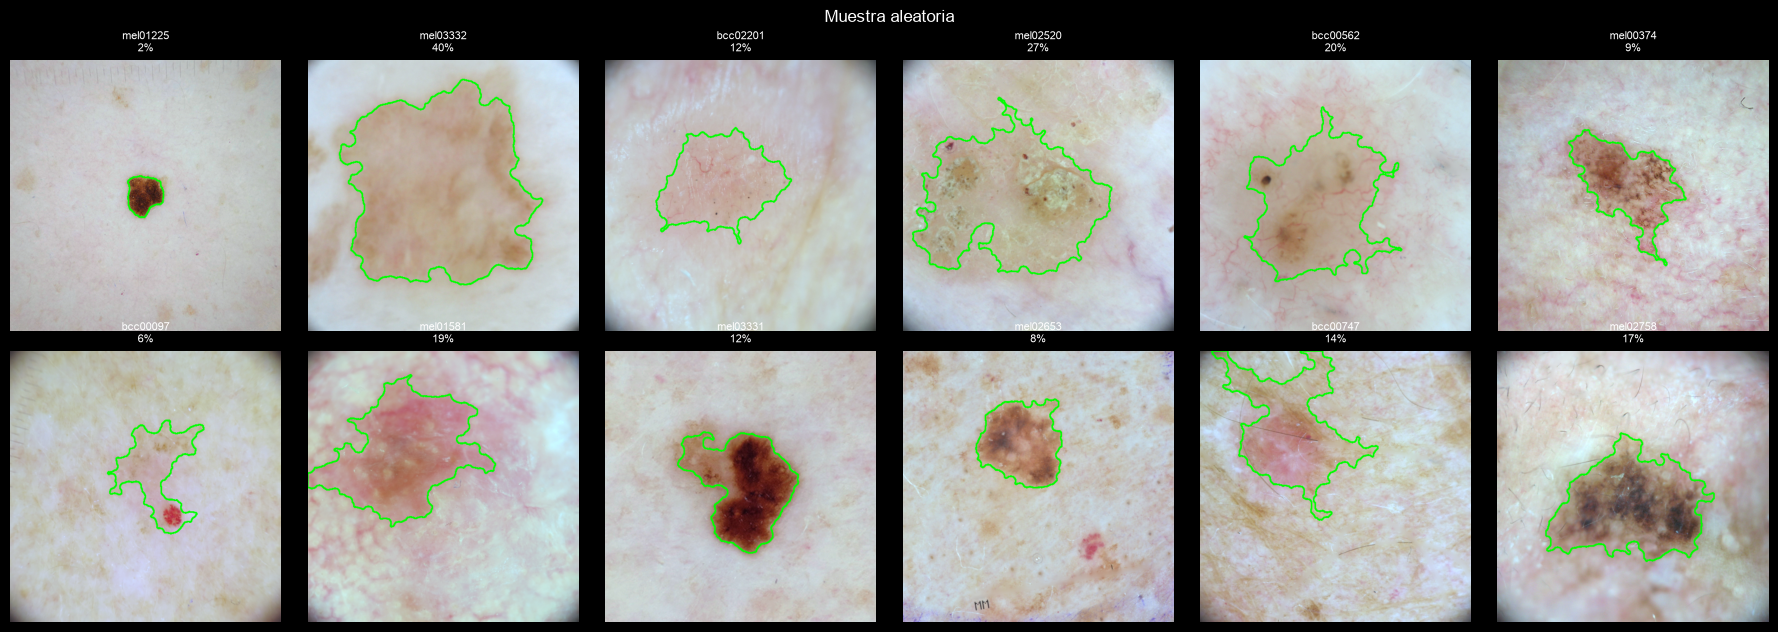

4202 imágenes con seg_ok == False (se muestran hasta 24)


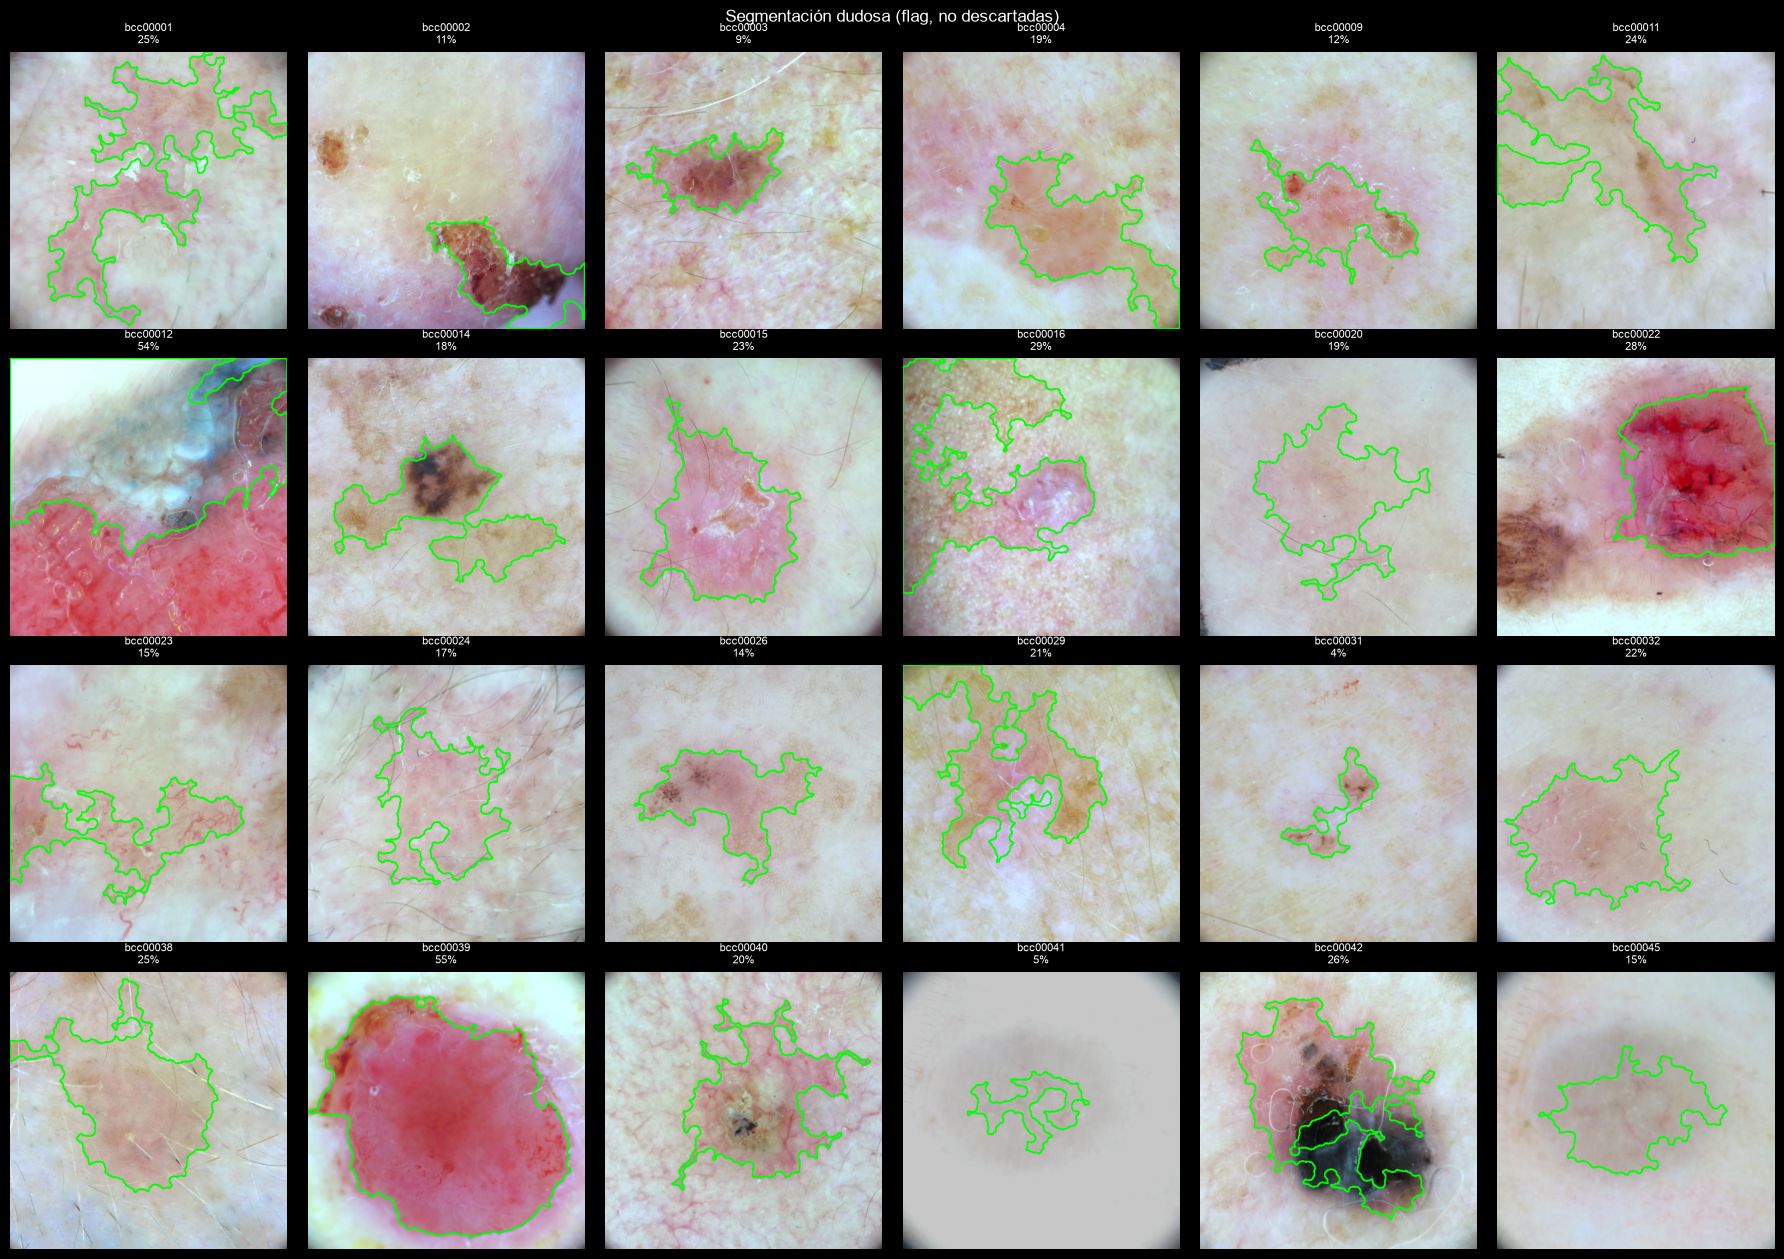

In [6]:
import matplotlib.pyplot as plt


def contour_overlay(img, mask, color=(0, 255, 0), thick=2):
    out = img.copy()
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cnts, -1, color, thick)
    return out


def contact_sheet(df, ncols=6, title=""):
    n = len(df)
    nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.2 * nrows), squeeze=False)
    for a in axs.ravel():
        a.axis("off")
    for a, (_, r) in zip(axs.ravel(), df.iterrows()):
        img = read_rgb(r["preprocessed"])
        m = cv2.imdecode(np.fromfile(r["mask"], np.uint8), cv2.IMREAD_GRAYSCALE) > 0
        a.imshow(contour_overlay(img, m))
        a.set_title(f"{r['name']}\n{100 * r['mask_area_frac']:.0f}%", fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


ok_rows = new[new["status"].isin(["ok", "skipped"])]
contact_sheet(ok_rows.sample(min(12, len(ok_rows)), random_state=SEED), title="Muestra aleatoria")
bad = ok_rows[~ok_rows["seg_ok"]]
print(f"{len(bad)} imágenes con seg_ok == False (se muestran hasta 24)")
if len(bad):
    contact_sheet(bad.head(24), title="Segmentación dudosa (flag, no descartadas)")